In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from langchain_chroma import Chroma
from langchain_ollama import OllamaEmbeddings, ChatOllama

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, AIMessage

from langchain_classic.chains import (
    create_history_aware_retriever,
    create_retrieval_chain,
)

from langchain_classic.chains.combine_documents import (
    create_stuff_documents_chain,
)


In [2]:
from langchain_classic.chains import (
    create_history_aware_retriever,
    create_retrieval_chain,
)

from langchain_classic.chains.combine_documents import (
    create_stuff_documents_chain,
)


In [3]:
BASE_DIR = Path.cwd()
CHROMA_DIR = BASE_DIR / "chroma_db"
COLLECTION_NAME = "resume"

EMBED_MODEL = "nomic-embed-text"
OLLAMA_BASE_URL = "http://localhost:11434"

TOP_K = 3

print("Database folder exists:", CHROMA_DIR.exists())


Database folder exists: True


In [4]:
embeddings = OllamaEmbeddings(model=EMBED_MODEL, base_url=OLLAMA_BASE_URL)

store = Chroma(
    collection_name=COLLECTION_NAME,
    embedding_function=embeddings,
    persist_directory=str(CHROMA_DIR),
    collection_metadata={"hnsw:space": "cosine"},
)

print("Resume chunks in database:", store._collection.count())
print("Metric:", store._collection.metadata)


Resume chunks in database: 6
Metric: {'hnsw:space': 'cosine'}


In [5]:
question = "What internships has Aakash done?"
print("User query:", question)


User query: What internships has Aakash done?


In [6]:
query_vector = embeddings.embed_query(question)

print("Dimensions:", len(query_vector))
print("First 5 numbers:", query_vector[:5])


Dimensions: 768
First 5 numbers: [-0.06662553, 0.055252913, -0.14639324, 0.027442183, 0.031228231]


In [7]:
# Fetch every stored vector, text and metadata from ChromaDB
data = store._collection.get(include=["embeddings", "documents", "metadatas"])

resume_vectors = np.array(data["embeddings"])   # shape: (number of chunks, 768)
q = np.array(query_vector)                      # shape: (768,)

# cosine similarity = dot(a, b) / (length(a) * length(b))
similarities = resume_vectors @ q / (
    np.linalg.norm(resume_vectors, axis=1) * np.linalg.norm(q)
)

# Sort all chunks from most similar to least similar
ranking = np.argsort(similarities)[::-1]

for rank, idx in enumerate(ranking, start=1):
    meta = data["metadatas"][idx]
    preview = data["documents"][idx][:55].replace("\n", " ")
    print(f"#{rank}  similarity={similarities[idx]:.3f}  chunk {meta['chunk_id']}: {preview}...")
    

#1  similarity=0.664  chunk 0: AAKASH MAHARANIDIN GUPTA  Electronics & Telecommunicati...
#2  similarity=0.649  chunk 5: Vanillakart | Digital Marketing Intern Dec'23 - Jan'24 ...
#3  similarity=0.627  chunk 4: INTERNSHIP  Manoeuvre Education | SEO Intern Aug'26 - P...
#4  similarity=0.489  chunk 1: databases, and document processing. Also experienced in...
#5  similarity=0.483  chunk 3: Features intelligent text chunking and dynamic retrieva...
#6  similarity=0.407  chunk 2: PROJECTS  RAG-Based Intelligent Document Chatbot | Pyth...


In [8]:
test_questions = [
    "What internships has Aakash done?",
    "What is Aakash's CGPA?",
    "Which programming languages does Aakash know?",
    "What is the capital of Japan?",
    "Who is the CEO of Google?",
]

for q in test_questions:

    results = store.similarity_search_with_relevance_scores(
        q,
        k=TOP_K
    )

    print("\nQuestion:", q)

    for doc, score in results:
        print(
            f"Chunk: {doc.metadata.get('chunk_id')} "
            f"| Relevance score: {score:.3f}"
        )
        


Question: What internships has Aakash done?
Chunk: 0 | Relevance score: 0.664
Chunk: 5 | Relevance score: 0.649
Chunk: 4 | Relevance score: 0.627

Question: What is Aakash's CGPA?
Chunk: 0 | Relevance score: 0.607
Chunk: 5 | Relevance score: 0.558
Chunk: 3 | Relevance score: 0.456

Question: Which programming languages does Aakash know?
Chunk: 0 | Relevance score: 0.709
Chunk: 1 | Relevance score: 0.550
Chunk: 5 | Relevance score: 0.539

Question: What is the capital of Japan?
Chunk: 0 | Relevance score: 0.360
Chunk: 5 | Relevance score: 0.341
Chunk: 3 | Relevance score: 0.331

Question: Who is the CEO of Google?
Chunk: 4 | Relevance score: 0.531
Chunk: 0 | Relevance score: 0.513
Chunk: 5 | Relevance score: 0.496


In [9]:
retriever = store.as_retriever(
    search_type="similarity",
    search_kwargs={"k": TOP_K},
)

top_docs = retriever.invoke(question)

print("Retriever returned:", len(top_docs), "chunks")

print(
    "Chunk IDs:",
    [doc.metadata.get("chunk_id") for doc in top_docs]
)



Retriever returned: 3 chunks
Chunk IDs: [0, 5, 4]


In [10]:
for i, doc in enumerate(top_docs, start=1):

    print(
        f"\n=== Relevant Chunk {i} "
        f"| chunk_id {doc.metadata.get('chunk_id')} "
        f"| page {doc.metadata.get('page', 0) + 1} ==="
    )

    print(doc.page_content)
    


=== Relevant Chunk 1 | chunk_id 0 | page 1 ===
AAKASH MAHARANIDIN GUPTA 
Electronics & Telecommunication Engineering 
+91-7559409264 | aakashguptamdeen41@gmail.com | MUMBAI 
LinkedIn | GitHub | LeetCode 
SUMMARY 
Electronics & Telecommunication Engineering graduate with hands-on expertise in Python, AI systems, and web development. 
Experienced in building RAG-based chatbots, desktop automation tools, and Flask applications. Proficient in LLM integration, vector

=== Relevant Chunk 2 | chunk_id 5 | page 1 ===
Vanillakart | Digital Marketing Intern Dec'23 - Jan'24 
• Performed keyword research using SEO tools and gained hands-on experience in website optimization and search engine ranking 
analysis. 
ACADEMIC QUALIFICATIONS 
Bachelor of Engineering (B.E.) 2021-2025 
University of Mumbai. CGPA: 6.83 
Higher Secondary School Certificate (H.S.C) Feb'20 
Maharashtra State Board. Score: 79.50% 
Secondary School Certificate (S.S.C) Mar'18 
Maharashtra State Board. Score: 78.40%

=== Relevant

In [11]:
def format_docs(docs):

    return "\n\n---\n\n".join(doc.page_content for doc in docs)

context = format_docs(top_docs)

print(context)


AAKASH MAHARANIDIN GUPTA 
Electronics & Telecommunication Engineering 
+91-7559409264 | aakashguptamdeen41@gmail.com | MUMBAI 
LinkedIn | GitHub | LeetCode 
SUMMARY 
Electronics & Telecommunication Engineering graduate with hands-on expertise in Python, AI systems, and web development. 
Experienced in building RAG-based chatbots, desktop automation tools, and Flask applications. Proficient in LLM integration, vector

---

Vanillakart | Digital Marketing Intern Dec'23 - Jan'24 
• Performed keyword research using SEO tools and gained hands-on experience in website optimization and search engine ranking 
analysis. 
ACADEMIC QUALIFICATIONS 
Bachelor of Engineering (B.E.) 2021-2025 
University of Mumbai. CGPA: 6.83 
Higher Secondary School Certificate (H.S.C) Feb'20 
Maharashtra State Board. Score: 79.50% 
Secondary School Certificate (S.S.C) Mar'18 
Maharashtra State Board. Score: 78.40%

---

INTERNSHIP 
Manoeuvre Education | SEO Intern Aug'26 - Present 
• Currently working on both on-pag

In [12]:
SYSTEM_PROMPT = """
You are an assistant that answers questions about the uploaded document.

Use ONLY the retrieved context below to answer.
Do not use outside knowledge. Do not invent information.

If the answer is not in the context, reply exactly:
I couldn't find that in the document.

Keep answers short, clear and accurate.
If the question refers to something said earlier, use the conversation history.

Retrieved context:

{context}
"""


prompt = ChatPromptTemplate.from_messages(
    [
        ("system", SYSTEM_PROMPT),
        ("human", "{question}"),
    ]
)

final_prompt = prompt.invoke({"context": context, "question": question})
print(final_prompt.to_string())


System: 
You are an assistant that answers questions about the uploaded document.

Use ONLY the retrieved context below to answer.
Do not use outside knowledge. Do not invent information.

If the answer is not in the context, reply exactly:
I couldn't find that in the document.

Keep answers short, clear and accurate.
If the question refers to something said earlier, use the conversation history.

Retrieved context:

AAKASH MAHARANIDIN GUPTA 
Electronics & Telecommunication Engineering 
+91-7559409264 | aakashguptamdeen41@gmail.com | MUMBAI 
LinkedIn | GitHub | LeetCode 
SUMMARY 
Electronics & Telecommunication Engineering graduate with hands-on expertise in Python, AI systems, and web development. 
Experienced in building RAG-based chatbots, desktop automation tools, and Flask applications. Proficient in LLM integration, vector

---

Vanillakart | Digital Marketing Intern Dec'23 - Jan'24 
• Performed keyword research using SEO tools and gained hands-on experience in website optimizati

# Phase 3: Generation

In [13]:
from langchain_core.output_parsers import StrOutputParser
from langchain_ollama import ChatOllama


In [14]:
LLM_MODEL = "mistral"

llm = ChatOllama(
    model=LLM_MODEL,
    base_url=OLLAMA_BASE_URL,
    temperature=0,
    keep_alive="30m",
)

print("Mistral LLM initialized successfully!")


Mistral LLM initialized successfully!


In [15]:
rephrase_prompt = ChatPromptTemplate.from_messages([

    (
        "system",
        """
        Given the conversation history and the latest user question,
        rewrite the question as a standalone question about Aakash's resume.

        Do not answer the question.

        If the question is already standalone,
        return it without changing its meaning.

        Do not add information that is not in the conversation.
        """
    ),

    MessagesPlaceholder(variable_name="chat_history"),

    ("human", "{input}"),

])


In [16]:
history_retriever = create_history_aware_retriever(
    llm,
    retriever,
    rephrase_prompt,
)


In [17]:
qa_prompt = ChatPromptTemplate.from_messages([

    ("system", SYSTEM_PROMPT),

    MessagesPlaceholder(variable_name="chat_history"),

    ("human", "{input}"),

])

qa_chain = create_stuff_documents_chain(
    llm,
    qa_prompt,
)

print("QA chain created successfully!")


QA chain created successfully!


In [18]:
conv_chain = create_retrieval_chain(
    history_retriever,
    qa_chain,
)

print("Conversational RAG chain created successfully!")


Conversational RAG chain created successfully!


In [19]:
print("Sources used:")
for d in top_docs:
    print(f"  - chunk {d.metadata['chunk_id']}, resume page {d.metadata['page'] + 1}")
    

Sources used:
  - chunk 0, resume page 1
  - chunk 5, resume page 1
  - chunk 4, resume page 1


In [20]:
import matplotlib.pyplot as plt


In [21]:
# 1. Put the resume vectors and the query vector in one array
all_vectors = np.vstack([resume_vectors, np.array(query_vector)])   # shape: (chunks + 1, 768)

# 2. Scale every vector to length 1, so only direction counts (like cosine does)
all_unit = all_vectors / np.linalg.norm(all_vectors, axis=1, keepdims=True)

# 3. PCA via SVD: find the 2 directions where the points spread out the most
centered = all_unit - all_unit.mean(axis=0)
U, S, Vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ Vt[:2].T                                         # shape: (chunks + 1, 2)

resume_xy = coords[:-1]     # all resume chunks
query_xy = coords[-1]       # the query (last row)

top3 = ranking[:3]          # positions of the 3 best chunks, from Cell 6

explained = (S**2 / np.sum(S**2))[:2]
print("Points plotted      :", len(coords))
print("Top 3 chunk indexes :", list(top3))
print(f"Information kept by the 2 axes: {explained.sum() * 100:.1f}%")


Points plotted      : 7
Top 3 chunk indexes : [np.int64(0), np.int64(5), np.int64(4)]
Information kept by the 2 axes: 55.8%


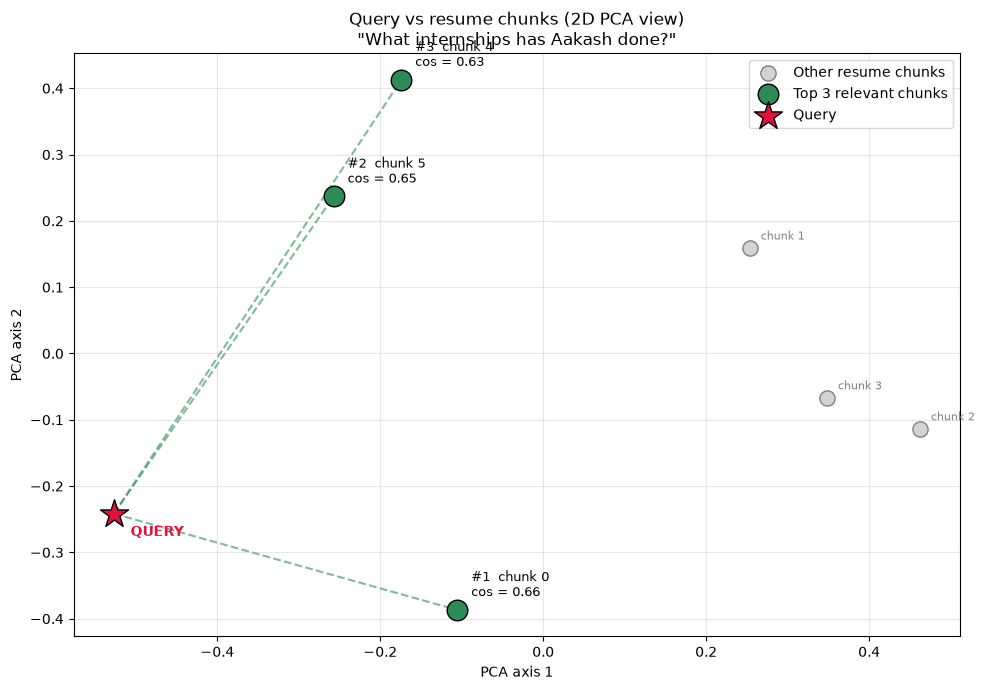

In [22]:
fig, ax = plt.subplots(figsize=(10, 7))

# All resume chunks (grey)
ax.scatter(resume_xy[:, 0], resume_xy[:, 1], s=120, color="lightgrey",
           edgecolor="grey", label="Other resume chunks", zorder=2)

# Top 3 chunks (green), with a line to the query
for rank, idx in enumerate(top3, start=1):
    x, y = resume_xy[idx]
    ax.scatter(x, y, s=220, color="seagreen", edgecolor="black", zorder=3,
               label="Top 3 relevant chunks" if rank == 1 else None)
    ax.plot([query_xy[0], x], [query_xy[1], y], linestyle="--", color="seagreen", alpha=0.6, zorder=1)
    ax.annotate(f"#{rank}  chunk {data['metadatas'][idx]['chunk_id']}\ncos = {similarities[idx]:.2f}",
                (x, y), textcoords="offset points", xytext=(10, 10), fontsize=9)

# The query (red star)
ax.scatter(query_xy[0], query_xy[1], s=450, marker="*", color="crimson",
           edgecolor="black", zorder=4, label="Query")
ax.annotate("QUERY", (query_xy[0], query_xy[1]), textcoords="offset points",
            xytext=(12, -16), fontsize=10, fontweight="bold", color="crimson")

# Label the other chunks lightly
for idx in range(len(resume_xy)):
    if idx not in top3:
        ax.annotate(f"chunk {data['metadatas'][idx]['chunk_id']}", resume_xy[idx],
                    textcoords="offset points", xytext=(8, 6), fontsize=8, color="grey")

ax.set_title(f'Query vs resume chunks (2D PCA view)\n"{question}"')
ax.set_xlabel("PCA axis 1")
ax.set_ylabel("PCA axis 2")
ax.grid(alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()


In [23]:
# Store conversation messages
chat_history = []

# Keep the latest 10 messages (5 question-answer exchanges)
MAX_HISTORY_MESSAGES = 10


def chat(question):

    try:

        # Run conversational RAG
        result = conv_chain.invoke({
            "input": question,
            "chat_history": chat_history,
        })

        # Get retrieved documents
        docs = result["context"]

        # Get generated answer
        answer = result["answer"]

        # Handle empty retrieval
        if not docs:
            answer = "I couldn't find that in the resume."

        # Save this exchange in chat history
        chat_history.extend([
            HumanMessage(content=question),
            AIMessage(content=answer),
        ])

        # Limit conversation history
        if len(chat_history) > MAX_HISTORY_MESSAGES:
            chat_history[:] = chat_history[-MAX_HISTORY_MESSAGES:]

        # Display answer
        print("\nQuestion:", question)
        print("\nAnswer:", answer)

        # Display sources
        print("\nSources used:")

        if docs:
            for doc in docs:

                chunk_id = doc.metadata.get("chunk_id", "Unknown")
                page = doc.metadata.get("page", 0) + 1

                print(
                    f"- Chunk {chunk_id}, Resume page {page}"
                )
        else:
            print("- No relevant sources found")

        print("-" * 60)

        return {
            "answer": answer,
            "sources": docs,
        }

    except Exception as e:

        print("Error while processing question:", e)

        return None
    

In [24]:
def reset_chat():
    chat_history.clear()
    print("Chat history cleared.")


In [25]:
chat("What internships has Aakash done?")

chat("What was his role at Eiosys?")

chat("Does Aakash know Java?")



Question: What internships has Aakash done?

Answer:  Aakash has done three internships: Vanillakart as a Digital Marketing Intern from Dec'23 to Jan'24, Eiosys as an SEO Intern from Jan'26 to Jun'26, and Manoeuvre Education as an SEO Intern from Aug'26 to the present.

Sources used:
- Chunk 0, Resume page 1
- Chunk 5, Resume page 1
- Chunk 4, Resume page 1
------------------------------------------------------------

Question: What was his role at Eiosys?

Answer:  His role at Eiosys was an SEO Intern.

Sources used:
- Chunk 4, Resume page 1
- Chunk 0, Resume page 1
- Chunk 5, Resume page 1
------------------------------------------------------------

Question: Does Aakash know Java?

Answer:  I couldn't find that Aakash knows Java in the provided context.

Sources used:
- Chunk 0, Resume page 1
- Chunk 5, Resume page 1
- Chunk 3, Resume page 1
------------------------------------------------------------


{'answer': " I couldn't find that Aakash knows Java in the provided context.",
 'sources': [Document(id='resume-chunk-0', metadata={'author': 'Un-named', 'moddate': '2026-09-23T13:46:51+00:00', 'page_label': '1', 'page': 0, 'producer': 'www.ilovepdf.com', 'total_pages': 1, 'source': 'c:\\Users\\ARTI\\Desktop\\Abhishek\\RAG-chatbot1\\aakash-resume.pdf', 'chunk_id': 0, 'creator': 'Microsoft® Word 2016', 'creationdate': '2026-09-23T13:46:51+00:00'}, page_content='AAKASH MAHARANIDIN GUPTA \nElectronics & Telecommunication Engineering \n+91-7559409264 | aakashguptamdeen41@gmail.com | MUMBAI \nLinkedIn | GitHub | LeetCode \nSUMMARY \nElectronics & Telecommunication Engineering graduate with hands-on expertise in Python, AI systems, and web development. \nExperienced in building RAG-based chatbots, desktop automation tools, and Flask applications. Proficient in LLM integration, vector'),
  Document(id='resume-chunk-5', metadata={'creationdate': '2026-09-23T13:46:51+00:00', 'source': 'c:\\User

In [26]:
reset_chat()

chat("What is Aakash's CGPA?")


Chat history cleared.

Question: What is Aakash's CGPA?

Answer:  6.83

Sources used:
- Chunk 0, Resume page 1
- Chunk 5, Resume page 1
- Chunk 3, Resume page 1
------------------------------------------------------------


{'answer': ' 6.83',
 'sources': [Document(id='resume-chunk-0', metadata={'author': 'Un-named', 'source': 'c:\\Users\\ARTI\\Desktop\\Abhishek\\RAG-chatbot1\\aakash-resume.pdf', 'creator': 'Microsoft® Word 2016', 'creationdate': '2026-09-23T13:46:51+00:00', 'chunk_id': 0, 'page': 0, 'moddate': '2026-09-23T13:46:51+00:00', 'page_label': '1', 'producer': 'www.ilovepdf.com', 'total_pages': 1}, page_content='AAKASH MAHARANIDIN GUPTA \nElectronics & Telecommunication Engineering \n+91-7559409264 | aakashguptamdeen41@gmail.com | MUMBAI \nLinkedIn | GitHub | LeetCode \nSUMMARY \nElectronics & Telecommunication Engineering graduate with hands-on expertise in Python, AI systems, and web development. \nExperienced in building RAG-based chatbots, desktop automation tools, and Flask applications. Proficient in LLM integration, vector'),
  Document(id='resume-chunk-5', metadata={'page': 0, 'creator': 'Microsoft® Word 2016', 'author': 'Un-named', 'moddate': '2026-09-23T13:46:51+00:00', 'chunk_id': 5, 